<b>DV Experiment 6: Pie and Donut Charts for Category Proportion</b><br><br><b>Aim:</b> Analyze Olympic medal share by country and continent using Pie and Donut proportion charts.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [2]:
data_dir = "datasets" if os.path.exists("datasets") else os.path.join("DV_Lab", "datasets")
out_dir = "outputs" if os.path.exists("outputs") else (os.path.join("DV_Lab", "outputs") if os.path.exists("DV_Lab") else "outputs")
os.makedirs(out_dir, exist_ok=True)

oly_df = pd.read_csv(os.path.join(data_dir, "olympic_medals.csv"))
oly_df["Share_Pct"] = (oly_df["Total"] / oly_df["Total"].sum() * 100.0).round(2)

In [3]:
print("Olympic Medal Share by Country:")
print(oly_df[["Country", "Gold", "Silver", "Bronze", "Total", "Share_Pct"]].to_string(index=False))

top7 = oly_df.sort_values("Total", ascending=False).head(7)
others_total = oly_df.sort_values("Total", ascending=False).iloc[7:]["Total"].sum()
pie_df = pd.concat([
    top7[["Country", "Total"]],
    pd.DataFrame([{"Country": "Others", "Total": others_total}]),
], ignore_index=True)

cont_df = oly_df.groupby("Continent", as_index=False)["Total"].sum().sort_values("Total", ascending=False)

Olympic Medal Share by Country:
      Country  Gold  Silver  Bronze  Total  Share_Pct
United States    40      44      42    126      19.27
        China    40      27      24     91      13.91
        Japan    20      12      13     45       6.88
    Australia    18      19      16     53       8.10
       France    16      26      22     64       9.79
  Netherlands    15       7      12     34       5.20
Great Britain    14      22      29     65       9.94
  South Korea    13       9      10     32       4.89
        Italy    12      13      15     40       6.12
      Germany    12      13       8     33       5.05
       Canada     9       7      11     27       4.13
       Brazil     3       7      10     20       3.06
        Spain     5       4       9     18       2.75
        India     0       1       5      6       0.92


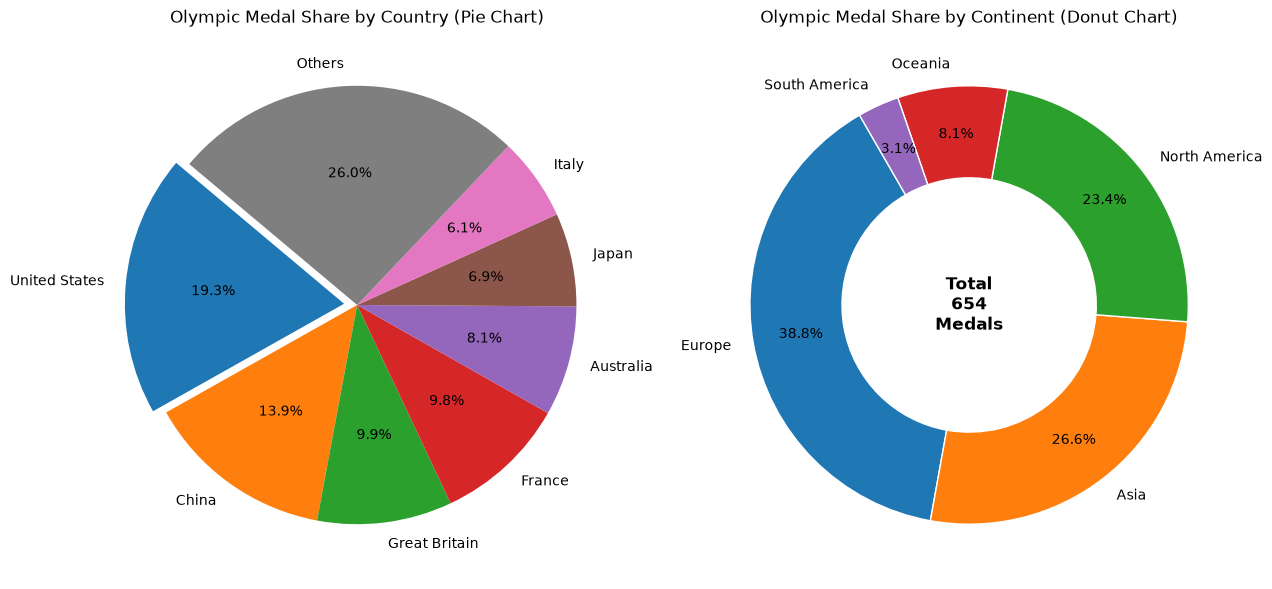

Interactive Pie/Donut HTML saved to: outputs\DV_Exp6_Interactive_Pie_Donut.html


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

explode = [0.06 if i == 0 else 0.0 for i in range(len(pie_df))]
axes[0].pie(
    pie_df["Total"],
    labels=pie_df["Country"],
    autopct="%1.1f%%",
    startangle=140,
    explode=explode,
    shadow=False,
)
axes[0].set_title("Olympic Medal Share by Country (Pie Chart)")

wedges, texts, autotexts = axes[1].pie(
    cont_df["Total"],
    labels=cont_df["Continent"],
    autopct="%1.1f%%",
    startangle=120,
    pctdistance=0.78,
    wedgeprops=dict(width=0.42, edgecolor="white"),
)
axes[1].text(0, 0, f"Total\n{oly_df['Total'].sum()}\nMedals", ha="center", va="center", fontsize=12, fontweight="bold")
axes[1].set_title("Olympic Medal Share by Continent (Donut Chart)")

plt.tight_layout()
plt.show()

interactive_fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "domain"}, {"type": "domain"}]],
    subplot_titles=("Country Medal Share (Pie)", "Continent Medal Share (Donut)"),
)
interactive_fig.add_trace(
    go.Pie(labels=pie_df["Country"], values=pie_df["Total"], hole=0.0, textinfo="label+percent"),
    row=1, col=1,
)
interactive_fig.add_trace(
    go.Pie(labels=cont_df["Continent"], values=cont_df["Total"], hole=0.52, textinfo="label+percent"),
    row=1, col=2,
)
interactive_fig.update_layout(height=500, width=1050, title_text="Olympic Medals Proportion Analysis")
html_path = os.path.join(out_dir, "DV_Exp6_Interactive_Pie_Donut.html")
interactive_fig.write_html(html_path, include_plotlyjs="cdn")
print("Interactive Pie/Donut HTML saved to:", html_path)

<b>Observation:</b> Consolidating smaller nations into Others prevents overlapping pie labels while the center-annotated donut highlights regional medal share.